In [11]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import math

In [12]:
class Point:
    x = None
    y = None

    def __init__(self,coor_x,coor_y):
        self.x=coor_x
        self.y=coor_y

    def __lt__(self, other):
      if(self.x != other.x):
        return self.x < other.x
      return self.y < other.y
    
    def plot(self, tag='', color=''): 
        kwargs = {} # A modification of the original class, allows passing independent arguments
        if color:
            kwargs['c'] = color
        if tag:
            kwargs['label'] = tag

        plt.scatter(self.x, self.y, **kwargs)
            
        if tag:
            plt.legend()
            
    def __repr__(self):
      return f"({self.x}, {self.y})"

In [13]:
class Segment:
    start = None
    end = None
    angle = None
    half = None

    def __init__(self, A, B ):
        if A < B:
            self.start = A
            self.end = B
        else:
            self.start = B
            self.end = A
    
        self.angle = self.calcAngle()
        self.half  = self.calcHalf()
        
    def __repr__(self):
      return f"[{self.start}, {self.end}]"

    def plot(self, tag='', color=''):
        kwargs = {} 
        if color:
            kwargs['c'] = color
        if tag:
            kwargs['label'] = tag

        segmento = [ [self.start.x, self.start.y ],  [self.end.x, self.end.y ] ]

        self.start.plot(**kwargs)
        self.end.plot(**kwargs)
        if color:
            plt.plot( [s[0] for s in segmento], [s[1] for s in segmento] ,  linestyle="-", color =color)
        else:
            plt.plot( [s[0] for s in segmento], [s[1] for s in segmento] ,  linestyle="-")

    def calcHalf(self):
        x = None
        y = None
        if(self.start.x == self.end.x): ## When the points are in the same x-axxis
            x = self.start.x
        else: 
            x = self.start.x + abs(self.start.x-self.end.x)/2

        if(self.start.y == self.end.y): # Both on the same y axxis
            y = self.start.y
        else:
            y = min(self.end.y,self.start.y) + abs(self.start.y-self.end.y)/2 

        
        print(f"start: {self.start}, end: {self.end}, half: ({x},{y})")
        return Point(x, y)


    def calcAngle(self):
        if(self.start.y == self.end.y): #Division by 0
            return 0
        if(self.start.x == self.end.x): # 90 degrees
            return float('inf')

        M = (self.start.x-self.end.x) / (self.start.y-self.end.y)
        return 
        


In [14]:
class Triangle:
    circumcenter = None
    circumradius = None


    def __init__(self,p1, p2,p3):

        self.points = []
        self.segments = []

        self.p1 = self.points.append(p1)
        self.p2 = self.points.append(p2)
        self.p3 = self.points.append(p3)
        self.segments.append(Segment(p1,p2))
        self.segments.append(Segment(p2,p3))
        self.segments.append(Segment(p3,p1))
        self.circumcenter, self.circumradius = self.calculateCircumcenter()


    def plot(self,ax):
        for p in self.points:
            p.plot()
            
        triangle_coords = [(p.x,p.y) for p in self.points]
        triangle = Polygon(triangle_coords, closed=True, facecolor='lightblue', edgecolor='darkgreen', alpha=0.6)
        ax.add_patch(triangle)
        
        self.circumcenter.plot(tag='Circumcenter', color='red') 
        circle = plt.Circle((self.circumcenter.x, self.circumcenter.y), self.circumradius, color='lightblue', fill=False, linestyle='-', linewidth=1)
        ax.add_patch(circle)

    def calculateCircumcenter(self):
        A = self.points[0]
        B = self.points[1]
        C = self.points[2]

        D = 2 * (A.x * (B.y - C.y) + B.x * (C.y - A.y) + C.x * (A.y - B.y))
        if D == 0:
            return None  # The points are collinear, circumcenter is undefined

        Ux = ((A.x**2 + A.y**2) * (B.y - C.y) + (B.x**2 + B.y**2) * (C.y - A.y) + (C.x**2 + C.y**2) * (A.y - B.y)) / D
        Uy = ((A.x**2 + A.y**2) * (C.x - B.x) + (B.x**2 + B.y**2) * (A.x - C.x) + (C.x**2 + C.y**2) * (B.x - A.x)) / D
        
        radio = math.sqrt((Ux - A.x)**2 + (Uy - A.y)**2)

        return Point(Ux, Uy), radio
    

start: (0, 0), end: (1, 0), half: (0.5,0)
start: (0.5, 1), end: (1, 0), half: (0.75,0.5)
start: (0, 0), end: (0.5, 1), half: (0.25,0.5)


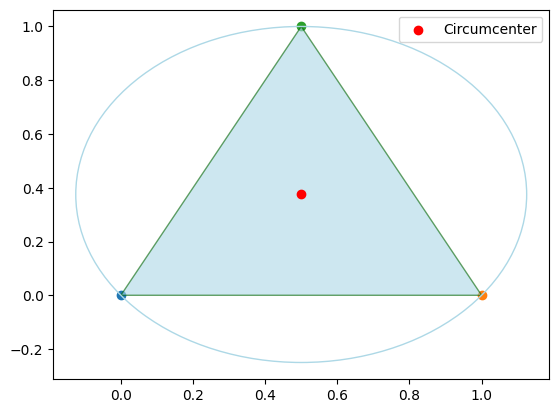

In [15]:
fig, ax = plt.subplots()
triangle = Triangle(Point(0, 0), Point(1, 0), Point(0.5, 1))
triangle.plot(ax)

start: (0, 0.5), end: (2, 3), half: (1.0,1.75)
start: (2, 3), end: (3.5, -1), half: (2.75,1.0)
start: (0, 0.5), end: (3.5, -1), half: (1.75,-0.25)


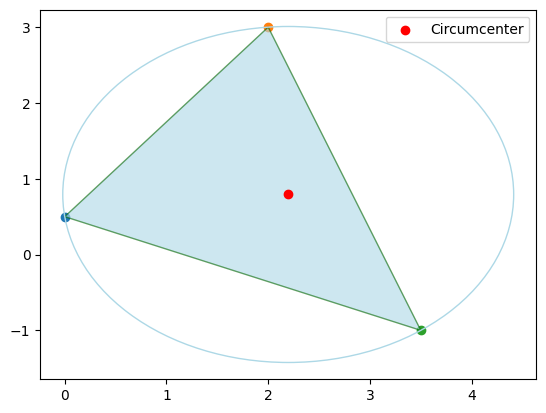

In [16]:
fig1, ax1 = plt.subplots()
triangle2 = Triangle(Point(0, 0.5), Point(2, 3), Point(3.5, -1))
triangle2.plot(ax1)